# Train B0 — YOLOv8s Batch 16 (100 epochs, imgsz=1024, no early-stop) — Kaggle GPU
**KLTN: PCB Defect Detection**

### Mục tiêu 
Notebook này chạy **Baseline B0** với `yolov8s.pt` và `batch=16`, giữ nguyên toàn bộ recipe từ `configs/base.yaml`:
- **Model**: `yolov8s.pt` (Small backbone: 11.2M tham số, CSPDarknet).
- **Resolution**: `imgsz=1024` (bảo toàn các lỗi vi mạch siêu nhỏ).
- **Optimizer & Scheduler**: `AdamW (lr0=0.001)` kết hợp `cos_lr=True` (Cosine Annealing).
- **Augmentation Domain PCB**: Bật lật 2 chiều (`flipud=0.5`, `fliplr=0.5`), `mosaic=0.8` và **`close_mosaic=15`**.
- **Zero Data Leakage**: Tách chuẩn theo bo mạch gốc 70/15/15: Train = 2416 ảnh, Val = 608 ảnh.
- **Run**: `B0_yolov8s_100ep_batch16`.

### Cấu trúc dataset Kaggle cần mount:
1. **Ảnh PKU**: `/kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)/`
2. **Project Data ZIP**: `pcb_b0_yolov8s_batch16_project_data.zip` (chứa `configs/base.yaml`, `data/splits/train.txt`, `data/splits/val.txt`, `split_info.json`)


## Cell 1 — Cài / upgrade ultralytics; gỡ ray để tránh conflict trên Kaggle.

In [17]:
!pip uninstall ray -y -q 2>/dev/null || True
!pip install ultralytics==8.3.40 -q --upgrade

## Cell 2 — Import thư viện; giải nén project bundle; kiểm tra đường dẫn dataset.

In [18]:
import json, hashlib, shutil, subprocess, sys, time, zipfile
from contextlib import redirect_stdout, redirect_stderr
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from IPython.display import display
from ultralytics import YOLO

# ── Kaggle dataset paths ──────────────────────────────────────────────────────
KAGGLE_IMG_ROOT_PREFERRED = Path(
    "/kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)"
)

WORK_DIR  = Path("/kaggle/working")
ZIP_NAME  = "pcb_b0_yolov8s_batch16_project_data.zip"

# ── Tìm và giải nén project bundle ────────────────────────────────────────────
input_root      = Path("/kaggle/input")
ZIP_NAME        = "pcb_b0_yolov8s_batch16_project_data.zip"
BUNDLE_DIR_NAME = "pcb_b0_yolov8s_batch16_project_data"
BUNDLE_ROOT     = WORK_DIR / BUNDLE_DIR_NAME

zip_candidates  = list(input_root.rglob(ZIP_NAME))

if len(zip_candidates) == 1:
    BUNDLE_ZIP = zip_candidates[0]
    with zipfile.ZipFile(BUNDLE_ZIP) as zf:
        bad = zf.testzip()
        assert bad is None, f"ZIP lỗi: {bad}"
        zf.extractall(WORK_DIR)
    print(f"✅ Giải nén bundle: {BUNDLE_ZIP}")
else:
    # Kaggle có thể mount nội dung ZIP đã giải nén thay vì giữ file .zip.
    bundle_candidates = []
    for cfg_path in input_root.rglob("base.yaml"):
        if cfg_path.parent.name != "configs":
            continue
        root = cfg_path.parent.parent
        if ((root/"data/splits/train.txt").is_file() and (root/"data/splits/val.txt").is_file()
                and (root/"split_info.json").is_file()):
            bundle_candidates.append(root)

    # Nếu có nhiều bundle (do add cả dataset cũ và mới), tự động ưu tiên bundle mới của YOLOv8s
    if len(bundle_candidates) > 1:
        matched = [b for b in bundle_candidates if BUNDLE_DIR_NAME in str(b) or "yolov8s" in str(b).lower()]
        if len(matched) == 1:
            bundle_candidates = matched

    assert len(bundle_candidates) == 1, (
        f"Không tìm thấy duy nhất project ZIP hoặc thư mục project-data đã giải nén; "
        f"zip={len(zip_candidates)}, folders={bundle_candidates[:5]}"
    )
    BUNDLE_ROOT = bundle_candidates[0]
    print(f"✅ Dùng bundle đã giải nén: {BUNDLE_ROOT}")


# ── Verify checksum split files ───────────────────────────────────────────────
split_info = json.loads((BUNDLE_ROOT/"split_info.json").read_text())
for split in ("train", "val"):
    split_bytes = (BUNDLE_ROOT/"data/splits"/f"{split}.txt").read_bytes()
    assert hashlib.md5(split_bytes).hexdigest() == split_info[f"{split}_txt_md5"], f"Checksum split {split} không khớp"
print("✅ Checksums split files OK")

# ── Tìm dataset PKU ───────────────────────────────────────────────────────────
if KAGGLE_IMG_ROOT_PREFERRED.is_dir():
    KAGGLE_IMG_ROOT = KAGGLE_IMG_ROOT_PREFERRED
else:
    candidates = [p for p in Path("/kaggle/input").rglob("PKU-Market-PCB(Data enhanced version)")
                  if (p/"train/images").is_dir() and (p/"train/labels").is_dir()]
    assert len(candidates) == 1, f"Không xác định duy nhất được thư mục PKU: {candidates[:5]}"
    KAGGLE_IMG_ROOT = candidates[0]

print("✅ Dataset ảnh:", KAGGLE_IMG_ROOT)
print(f"   Train images: {len(list((KAGGLE_IMG_ROOT/'train'/'images').glob('*.jpg')))}")
print(f"   Valid images: {len(list((KAGGLE_IMG_ROOT/'valid'/'images').glob('*.jpg')))}")
print(f"   Test images : {len(list((KAGGLE_IMG_ROOT/'test' /'images').glob('*.jpg')))}")
print()
print("✅ GPU:", [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
assert torch.cuda.is_available(), "Hãy bật GPU trong Kaggle Notebook Settings."

✅ Dùng bundle đã giải nén: /kaggle/input/datasets/tanthongthai/pcb-kaggle-b0-yolov8s-batch16/pcb_b0_yolov8s_batch16_project_data
✅ Checksums split files OK
✅ Dataset ảnh: /kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)
   Train images: 2772
   Valid images: 366
   Test images : 366

✅ GPU: ['Tesla T4', 'Tesla T4']


# Cell 3 — Load hyperparams từ configs/base.yaml; thiết lập cấu hình B0 YOLOv8s batch 16.

In [19]:
cfg = yaml.safe_load((BUNDLE_ROOT / "configs" / "base.yaml").read_text())
print("✅ Loaded configs/base.yaml:", cfg)

CLASSES   = ["Missing_hole", "Mouse_bite", "Open_circuit", "Short", "Spur", "Spurious_copper"]

# ===== CẤU HÌNH B0 YOLOv8s BATCH 16 =====
MODEL     = "yolov8s.pt"               # Override sang YOLOv8s (11.2M params, CSPDarknet)
EPOCHS    = int(cfg["epochs"])         # 100 epochs
PATIENCE  = int(cfg["patience"])       # = EPOCHS → KHÔNG dừng sớm
BATCH     = 16                         # Batch size 16
IMGSZ     = int(cfg["imgsz"])          # 1024x1024 — bảo tồn chi tiết lỗi vi mô
SEED      = int(cfg["seed"])           # 42
OPTIMIZER = str(cfg["optimizer"])      # AdamW
AUG       = cfg["augmentation"]
RUN_NAME  = "B0_yolov8s_100ep_batch16"
RUNS_DIR  = WORK_DIR / "runs"
# ==========================================

print(f"\nHyperparams sẽ dùng cho {RUN_NAME}:")
print(f"  model    : {MODEL}  (YOLOv8s — CSPDarknet backbone)")
print(f"  imgsz    : {IMGSZ}  (1024x1024 — bắt trọn lỗi vi mô PCB)")
print(f"  epochs   : {EPOCHS}  (100 epochs, không early-stop)")
print(f"  patience : {PATIENCE}")
print(f"  batch    : {BATCH}")
print(f"  seed     : {SEED}")
print(f"  optimizer: {OPTIMIZER}")

✅ Loaded configs/base.yaml: {'experiment_name': 'B0_yolo11', 'model': 'yolo11s.pt', 'data': 'data/data.yaml', 'imgsz': 1024, 'epochs': 100, 'batch': 16, 'seed': 42, 'patience': 100, 'optimizer': 'AdamW', 'device': 0, 'augmentation': {'degrees': 0.0, 'shear': 0.0, 'perspective': 0.0, 'flipud': 0.5, 'fliplr': 0.5, 'mosaic': 0.8, 'close_mosaic': 15, 'hsv_h': 0.015, 'hsv_s': 0.7, 'hsv_v': 0.4}, 'predict_conf': 0.25, 'predict_iou': 0.7}

Hyperparams sẽ dùng cho B0_yolov8s_100ep_batch16:
  model    : yolov8s.pt  (YOLOv8s — CSPDarknet backbone)
  imgsz    : 1024  (1024x1024 — bắt trọn lỗi vi mô PCB)
  epochs   : 100  (100 epochs, không early-stop)
  patience : 100
  batch    : 16
  seed     : 42
  optimizer: AdamW


# Cell 4 — Load split files; remap đường dẫn local → Kaggle absolute path; kiểm tra nhãn.

In [20]:
LOCAL_PREFIX = "data/raw/PKU-Market-PCB(Data enhanced version)/"

def remap_split(name: str) -> list:
    """
    Đọc split .txt, remap sang Kaggle absolute path.
    Kiểm tra ảnh và nhãn tồn tại; đảm bảo class_id hợp lệ.
    """
    src = BUNDLE_ROOT / "data" / "splits" / f"{name}.txt"
    assert src.is_file(), f"Thiếu split list: {src}"
    output = []
    for line in src.read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if not line:
            continue
        assert line.startswith(LOCAL_PREFIX), f"Đường dẫn ngoài dataset PKU: {line}"
        rel = line[len(LOCAL_PREFIX):]
        img = KAGGLE_IMG_ROOT / rel
        assert img.is_file(), f"Không thấy ảnh theo split {name}: {img}"
        label = img.parent.parent / "labels" / f"{img.stem}.txt"
        assert label.is_file(), f"Không thấy nhãn gốc của ảnh: {label}"
        output.append(str(img))
    return output

train_paths = remap_split("train")
val_paths   = remap_split("val")

assert len(train_paths) == 2416 and len(val_paths) == 608, (
    f"Số ảnh không khớp: train={len(train_paths)}, val={len(val_paths)}"
)
assert len(set(train_paths)) == len(train_paths) and len(set(val_paths)) == len(val_paths), \
    "Có ảnh trùng lặp trong split"

print(f"✅ Loaded splits: train={len(train_paths)}, val={len(val_paths)}")
print(f"✅ train: 5 sample paths tồn tại")
print(f"✅ val: 5 sample paths tồn tại")

# ── Kiểm tra class_id và thống kê GT ─────────────────────────────────────────
class_counts = {i: 0 for i in range(6)}
for image_path in train_paths + val_paths:
    image = Path(image_path)
    label = image.parent.parent / "labels" / f"{image.stem}.txt"
    for row in label.read_text(encoding="utf-8").splitlines():
        if row.strip():
            cid = int(row.split()[0])
            assert 0 <= cid < 6, f"class_id không hợp lệ: {label}: {cid}"
            class_counts[cid] += 1
assert all(v > 0 for v in class_counts.values()), f"Có lớp không có box: {class_counts}"
print("\n✅ Thống kê GT boxes (train + val):")
display(pd.DataFrame([{"class_id": i, "class": CLASSES[i], "GT boxes train+val": class_counts[i]} for i in range(6)]))

✅ Loaded splits: train=2416, val=608
✅ train: 5 sample paths tồn tại
✅ val: 5 sample paths tồn tại

✅ Thống kê GT boxes (train + val):


,class_id,class,GT boxes train+val
0,0,Missing_hole,2026
1,1,Mouse_bite,2010
2,2,Open_circuit,1934
3,3,Short,1992
4,4,Spur,1982
5,5,Spurious_copper,2058


# Cell 5 — Ghi split files vào working dir; tạo data_kaggle_train_val.yaml cho training.

In [21]:
WORK_DIR.mkdir(parents=True, exist_ok=True)
splits_dir = WORK_DIR / "splits"
splits_dir.mkdir(exist_ok=True)

train_txt_kaggle = splits_dir / "train.txt"
val_txt_kaggle   = splits_dir / "val.txt"

train_txt_kaggle.write_text("\n".join(train_paths) + "\n", encoding="utf-8")
val_txt_kaggle.write_text(  "\n".join(val_paths)   + "\n", encoding="utf-8")

print(f"✅ Wrote train.txt: {len(train_paths)} images")
print(f"✅ Wrote val.txt  : {len(val_paths)} images")

# ── Tạo data.yaml chỉ có train/val (test KHÔNG được thêm) ─────────────────────
DATA_YAML = WORK_DIR / "data_kaggle_train_val.yaml"
data_cfg  = {
    "path"  : str(KAGGLE_IMG_ROOT),
    "train" : str(train_txt_kaggle),
    "val"   : str(val_txt_kaggle),
    # test KHÔNG được thêm để tránh data leakage
    "nc"    : 6,
    "names" : {i: name for i, name in enumerate(CLASSES)},
}
DATA_YAML.write_text(
    yaml.safe_dump(data_cfg, sort_keys=False, allow_unicode=True),
    encoding="utf-8"
)

print(f"\n✅ data_kaggle_train_val.yaml:")
print(DATA_YAML.read_text())

✅ Wrote train.txt: 2416 images
✅ Wrote val.txt  : 608 images

✅ data_kaggle_train_val.yaml:
path: /kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data
  enhanced version)
train: /kaggle/working/splits/train.txt
val: /kaggle/working/splits/val.txt
nc: 6
names:
  0: Missing_hole
  1: Mouse_bite
  2: Open_circuit
  3: Short
  4: Spur
  5: Spurious_copper



# Cell 6 — Fix Ray Tune incompatibility — PHẢI chạy trước model.train().

In [22]:
import ultralytics.utils.callbacks.raytune as _raytune_cb
_raytune_cb.callbacks.clear()              # Xóa sạch callback registry
_raytune_cb.on_fit_epoch_end = lambda trainer: None  # Phòng reference cũ đã cache
print("✅ Disabled ultralytics raytune callback registry")

try:
    import ray.train._internal.session as _ray_session
    if not hasattr(_ray_session, '_get_session'):
        _ray_session._get_session = lambda: None
        print("✅ Patched ray._get_session")
except Exception as e:
    print(f"ray patch skipped: {e}")

✅ Disabled ultralytics raytune callback registry
ray patch skipped: No module named 'ray'


# Cell 7 — Train B0_yolov8s_100ep_batch16 — YOLOv8s (1024x1024, batch=16, Cosine LR, Close Mosaic 15 ep)

In [23]:
RUN_DIR  = RUNS_DIR / RUN_NAME
last_pt  = RUN_DIR / "weights" / "last.pt"

# Bật FORCE_FRESH_START = True để train mới hoàn toàn với YOLOv8s (1024x1024)
FORCE_FRESH_START = True
RESUME = (not FORCE_FRESH_START) and last_pt.is_file()

assert not RUN_DIR.exists() or FORCE_FRESH_START, (
    f"Không ghi đè run đã tồn tại: {RUN_DIR}; đổi RUN_NAME nếu chủ động tạo run khác."
)

if RESUME:
    print(f"⚠️  Tìm thấy last.pt → Resume từ checkpoint: {last_pt}")
    model = YOLO(str(last_pt))
else:
    if FORCE_FRESH_START and RUN_DIR.exists():
        print(f"🧹 Làm sạch runs cũ để train mới hoàn toàn với {MODEL} (imgsz={IMGSZ}) ...")
        shutil.rmtree(RUN_DIR, ignore_errors=True)
    print(f"Khởi tạo B0 từ pretrained {MODEL} ...")
    model = YOLO(MODEL)

# Loại bỏ raytune callback khỏi instance model
model.callbacks['on_fit_epoch_end'] = [
    cb for cb in model.callbacks['on_fit_epoch_end']
    if not cb.__module__.endswith('.raytune')
]
print("✅ Tiếp tục từ last.pt" if RESUME else f"✅ Khởi tạo {RUN_NAME} từ {MODEL}")

t0         = time.time()
trained_at = datetime.now(timezone.utc).isoformat()

print(f"\n=== BẮT ĐẦU HUẤN LUYỆN B0 YOLOv8s BATCH 16 ({EPOCHS} EPOCHS, IMGSZ={IMGSZ}, BATCH={BATCH}) ===")

# ── Ghi log song song vào training.log ───────────────────────────────────────
class Tee:
    def __init__(self, *streams): self.streams = streams
    def write(self, text):
        for stream in self.streams:
            stream.write(text); stream.flush()
        return len(text)
    def flush(self):
        for stream in self.streams: stream.flush()

log_path = WORK_DIR / "training.log"
with log_path.open("w", encoding="utf-8") as log_file:
    stdout0, stderr0 = sys.stdout, sys.stderr
    with redirect_stdout(Tee(stdout0, log_file)), redirect_stderr(Tee(stderr0, log_file)):
        results = model.train(
            data          = str(DATA_YAML),
            epochs        = EPOCHS,
            batch         = BATCH,
            imgsz         = IMGSZ,
            seed          = SEED,
            patience      = PATIENCE,    # 100 → không dừng sớm
            optimizer     = OPTIMIZER,   # AdamW
            lr0           = 0.001,
            lrf           = 0.01,
            cos_lr        = True,        # Cosine Learning Rate Schedule
            project       = str(RUNS_DIR),
            name          = RUN_NAME,
            device        = 0,
            verbose       = True,
            save          = True,
            plots         = True,
            exist_ok      = True,
            workers       = 2,
            deterministic = True,
            val           = True,
            resume        = str(last_pt) if RESUME else False,
            close_mosaic  = 15,          # Tắt Mosaic ở 15 epoch cuối để hội tụ sắc nét
            # ── Augmentation tối ưu cho bo mạch PCB ──────────────────────────
            degrees       = float(AUG["degrees"]),    # Không xoay nghiêng méo góc
            shear         = float(AUG["shear"]),
            perspective   = float(AUG["perspective"]),
            flipud        = float(AUG["flipud"]),     # Bật lật dọc cho bo mạch
            fliplr        = float(AUG["fliplr"]),     # Lật ngang
            mosaic        = float(AUG["mosaic"]),     # Giảm nhẹ mosaic
            mixup         = 0.0,
            copy_paste    = 0.0,
            hsv_h         = float(AUG["hsv_h"]),
            hsv_s         = float(AUG["hsv_s"]),
            hsv_v         = float(AUG["hsv_v"]),
            scale         = 0.5,
            translate     = 0.1,
        )

elapsed = time.time() - t0

best_pt = RUN_DIR / "weights" / "best.pt"
if not best_pt.is_file():
    raise FileNotFoundError("Train chưa hoàn tất: không có best.pt")

print(f"\n{'='*60}")
print(f"Training hoàn tất! Elapsed: {elapsed/60:.1f} phút")
print(f"{'='*60}")

m = results.results_dict
print(f"mAP50    : {m.get('metrics/mAP50(B)',    0):.4f}")
print(f"mAP50-95 : {m.get('metrics/mAP50-95(B)',0):.4f}")
print(f"Precision: {m.get('metrics/precision(B)',0):.4f}")
print(f"Recall   : {m.get('metrics/recall(B)',   0):.4f}")

Khởi tạo B0 từ pretrained yolov8s.pt ...


100%|██████████| 21.5M/21.5M [00:00<00:00, 100MB/s] 


✅ Khởi tạo B0_yolov8s_100ep_batch16 từ yolov8s.pt

=== BẮT ĐẦU HUẤN LUYỆN B0 YOLOv8s BATCH 16 (100 EPOCHS, IMGSZ=1024, BATCH=16) ===
New https://pypi.org/project/ultralytics/8.4.183 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.40 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: task=detect, mode=train, model=yolov8s.pt, data=/kaggle/working/data_kaggle_train_val.yaml, epochs=100, time=None, patience=100, batch=16, imgsz=1024, save=True, save_period=-1, cache=False, device=0, workers=2, project=/kaggle/working/runs, name=B0_yolov8s_100ep_batch16, exist_ok=True, pretrained=True, optimizer=AdamW, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=True, close_mosaic=15, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=Fals

train: Scanning /kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)/test/labels... 2416 images, 0 backgrounds, 0 corrupt: 100%|##########| 2416/2416 [00:03<00:00, 764.12it/s]


train: WARNING ⚠️ Cache directory /kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)/test is not writeable, cache not saved.


/usr/local/lib/python3.12/dist-packages/ultralytics/data/augment.py:1850: UserWarning: Argument(s) 'quality_lower' are not valid for transform ImageCompression
  A.ImageCompression(quality_lower=75, p=0.0),


... (199 outputs left out)

    100/100      9.24G     0.6594     0.3393     0.8331         53       1024: 100%|##########| 151/151 [01:59<00:00,  1.27it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|##########| 19/19 [00:18<00:00,  1.00it/s]


                   all        608       3060      0.785      0.877      0.828       0.39

100 epochs completed in 3.951 hours.
Optimizer stripped from /kaggle/working/runs/B0_yolov8s_100ep_batch16/weights/last.pt, 22.6MB
Optimizer stripped from /kaggle/working/runs/B0_yolov8s_100ep_batch16/weights/best.pt, 22.6MB

Validating /kaggle/working/runs/B0_yolov8s_100ep_batch16/weights/best.pt...
Ultralytics 8.3.40 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 168 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|##########| 19/19 [00:20<00:00,  1.06s/it]


                   all        608       3060      0.788      0.847      0.838      0.417
          Missing_hole        100        508      0.126      0.974      0.544      0.286
            Mouse_bite        100        504       0.92      0.843      0.892      0.417
          Open_circuit        104        524      0.913      0.864      0.896      0.465
                 Short        100        496      0.947      0.824      0.931      0.462
                  Spur        100        500      0.968      0.663      0.836      0.389
       Spurious_copper        104        528      0.853      0.913      0.931      0.482
Speed: 0.4ms preprocess, 10.5ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /kaggle/working/runs/B0_yolov8s_100ep_batch16

Training hoàn tất! Elapsed: 237.7 phút
mAP50    : 0.8381
mAP50-95 : 0.4168
Precision: 0.7877
Recall   : 0.8468


# Cell 8 — Validation tổng quan và bảng baseline theo lớp.

In [24]:
val_start   = time.time()
val_metrics = model.val(
    data    = str(DATA_YAML),
    split   = "val",
    imgsz   = IMGSZ,
    batch   = BATCH,
    device  = 0,
    conf    = 0.001,
    iou     = 0.7,
    plots   = True,
    project = str(RUNS_DIR),
    name    = f"{RUN_NAME}_validation",
    exist_ok= True,
    verbose = True,
)
val_elapsed_sec = time.time() - val_start

box           = val_metrics.box
class_indices = [int(x) for x in box.ap_class_index]
class_rows    = []
for cid, name in enumerate(CLASSES):
    if cid in class_indices:
        j   = class_indices.index(cid)
        p, r, ap50, ap = float(box.p[j]), float(box.r[j]), float(box.ap50[j]), float(box.ap[j])
    else:
        p = r = ap50 = ap = 0.0
    f1 = 2 * p * r / (p + r + 1e-12)
    class_rows.append({"class_id": cid, "class": name, "Precision": p, "Recall": r,
                       "F1": f1, "mAP50": ap50, "mAP50-95": ap})

overall = pd.DataFrame([{
    "Model": MODEL, "Split": "validation", "Images": len(val_paths),
    "Batch": BATCH, "imgsz": IMGSZ, "Epoch budget": EPOCHS,
    "mAP@0.5": float(box.map50), "mAP@0.5:0.95": float(box.map),
    "Mean Precision": float(box.mp), "Mean Recall": float(box.mr),
    "best.pt MB": best_pt.stat().st_size / 1e6, "Val time (s)": val_elapsed_sec,
}])
print("BASELINE TỔNG QUAN — VALIDATION"); display(overall.round(4))
print("METRICS THEO SÁU LỚP — VALIDATION"); display(pd.DataFrame(class_rows).round(4))
print("Confusion matrix, PR curve, results.csv:", val_metrics.save_dir)

Ultralytics 8.3.40 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 168 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs


val: Scanning /kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)/train/labels... 608 images, 0 backgrounds, 0 corrupt: 100%|██████████| 608/608 [00:00<00:00, 757.76it/s]


val: WARNING ⚠️ Cache directory /kaggle/input/datasets/liuxiaolong1/pcb-defect-detection-dataset/PKU-Market-PCB(Data enhanced version)/train is not writeable, cache not saved.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 38/38 [00:23<00:00,  1.63it/s]


                   all        608       3060      0.789      0.846      0.838      0.418
          Missing_hole        100        508      0.124      0.974      0.546      0.288
            Mouse_bite        100        504       0.92      0.844      0.891      0.418
          Open_circuit        104        524      0.919      0.864      0.897      0.468
                 Short        100        496      0.944      0.818      0.927      0.462
                  Spur        100        500      0.971      0.663      0.838      0.388
       Spurious_copper        104        528      0.853      0.913      0.931      0.484
Speed: 0.5ms preprocess, 22.4ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to /kaggle/working/runs/B0_yolov8s_100ep_batch16_validation
BASELINE TỔNG QUAN — VALIDATION


,Model,Split,Images,Batch,imgsz,Epoch budget,mAP@0.5,mAP@0.5:0.95,Mean Precision,Mean Recall,best.pt MB,Val time (s)
0,yolov8s.pt,validation,608,16,1024,100,0.8381,0.4179,0.7885,0.8461,22.6056,27.9035


METRICS THEO SÁU LỚP — VALIDATION


,class_id,class,Precision,Recall,F1,mAP50,mAP50-95
0,0,Missing_hole,0.1245,0.9744,0.2208,0.5461,0.2884
1,1,Mouse_bite,0.9200,0.8437,0.8802,0.8908,0.4178
2,2,Open_circuit,0.9188,0.8642,0.8907,0.8965,0.4679
3,3,Short,0.9442,0.8184,0.8768,0.9271,0.4619
4,4,Spur,0.9707,0.6628,0.7878,0.8375,0.3879
5,5,Spurious_copper,0.8531,0.9128,0.8819,0.9308,0.4836


Confusion matrix, PR curve, results.csv: /kaggle/working/runs/B0_yolov8s_100ep_batch16_validation


# Cell 9 — FN ban đầu theo lớp và kích thước.

Dùng size bin đã khóa trong `docs/01-Reports/decision_log.md`: diện tích box quy đổi về ảnh 640×640; small `<32²`, medium `32²–96²` (gồm biên), large `>96²`. Đếm FN bằng greedy matching class-aware, IoU≥0.50, confidence=0.25. Đây là phân tích lỗi ở một threshold tham khảo, tách biệt với mAP.

FN/Recall theo lớp × kích thước — val, conf=.25, IoU=.50


,class,size_bin,GT,TP,FN,Recall
0,Missing_hole,small,467,457,10,0.9786
1,Missing_hole,medium,41,41,0,1.0000
2,Missing_hole,large,0,0,0,NaN
3,Mouse_bite,small,480,429,51,0.8938
4,Mouse_bite,medium,24,21,3,0.8750
5,Mouse_bite,large,0,0,0,NaN
6,Open_circuit,small,497,453,44,0.9115
7,Open_circuit,medium,27,25,2,0.9259
8,Open_circuit,large,0,0,0,NaN
9,Short,small,369,358,11,0.9702


,GT,TP,FN,Recall
size_bin,,,,
small,2769,2518,251,0.9094
medium,291,247,44,0.8488
large,0,0,0,NaN


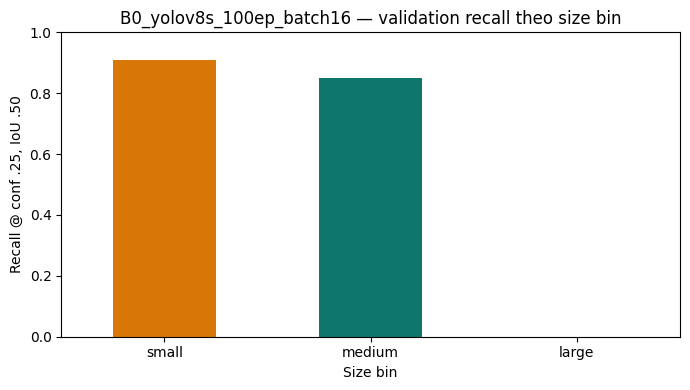

GT=0 nghĩa là không có mẫu của bin; recall là N/A, không phải 0.


In [25]:
SIZE_BINS = ["small", "medium", "large"]

def label_for_image(image_path):
    return image_path.parent.parent / "labels" / f"{image_path.stem}.txt"

def get_size_bin(w_norm, h_norm, image_w, image_h):
    area_640 = (w_norm * image_w) * (h_norm * image_h) / (image_w * image_h) * 640**2
    return "small" if area_640 < 32**2 else ("medium" if area_640 <= 96**2 else "large")

def iou_xyxy(a, b):
    x1 = np.maximum(a[:,None,0], b[None,:,0]); y1 = np.maximum(a[:,None,1], b[None,:,1])
    x2 = np.minimum(a[:,None,2], b[None,:,2]); y2 = np.minimum(a[:,None,3], b[None,:,3])
    inter = np.maximum(0, x2-x1) * np.maximum(0, y2-y1)
    aa = np.maximum(0, a[:,2]-a[:,0]) * np.maximum(0, a[:,3]-a[:,1])
    ba = np.maximum(0, b[:,2]-b[:,0]) * np.maximum(0, b[:,3]-b[:,1])
    return inter / (aa[:,None] + ba[None,:] - inter + 1e-9)

counts = {(c, s): {"GT": 0, "TP": 0} for c in range(6) for s in SIZE_BINS}
for image_path_str in val_paths:
    image_path = Path(image_path_str)
    label_path = label_for_image(image_path)
    pred = next(model.predict(source=str(image_path), imgsz=IMGSZ, batch=1, device=0,
                              conf=0.25, iou=0.7, verbose=False, stream=True))
    ih, iw = pred.orig_shape
    gt_boxes = []; gt_cls = []; gt_bins = []
    for line in label_path.read_text(encoding="utf-8").splitlines():
        if not line.strip(): continue
        cid, xc, yc, wn, hn = map(float, line.split()[:5])
        gt_boxes.append([(xc-wn/2)*iw, (yc-hn/2)*ih, (xc+wn/2)*iw, (yc+hn/2)*ih])
        gt_cls.append(int(cid))
        gt_bins.append(get_size_bin(wn, hn, iw, ih))
        counts[(int(cid), gt_bins[-1])]["GT"] += 1
    boxes = pred.boxes
    pb = boxes.xyxy.cpu().numpy()        if boxes is not None else np.empty((0, 4))
    pc = boxes.cls.cpu().numpy().astype(int) if boxes is not None else np.empty(0, dtype=int)
    ps = boxes.conf.cpu().numpy()        if boxes is not None else np.empty(0)
    matched = set()
    for pi in np.argsort(-ps):
        candidates = [gi for gi, cid in enumerate(gt_cls) if cid == pc[pi] and gi not in matched]
        if not candidates: continue
        vals = iou_xyxy(pb[pi:pi+1], np.asarray(gt_boxes)[candidates])[0]
        pos  = int(np.argmax(vals))
        if vals[pos] >= 0.50:
            gi = candidates[pos]; matched.add(gi); counts[(gt_cls[gi], gt_bins[gi])]["TP"] += 1

rows = []
for cid, name in enumerate(CLASSES):
    for size in SIZE_BINS:
        d  = counts[(cid, size)]; fn = d["GT"] - d["TP"]
        rows.append({"class": name, "size_bin": size, "GT": d["GT"], "TP": d["TP"], "FN": fn,
                     "Recall": d["TP"] / d["GT"] if d["GT"] else np.nan})
size_df = pd.DataFrame(rows)
print("FN/Recall theo lớp × kích thước — val, conf=.25, IoU=.50"); display(size_df.round(4))
size_summary = size_df.groupby("size_bin").agg(GT=("GT", "sum"), TP=("TP", "sum"), FN=("FN", "sum"))
size_summary["Recall"] = size_summary.TP / size_summary.GT.replace(0, np.nan)
display(size_summary.reindex(SIZE_BINS).round(4))
ax = size_summary.reindex(SIZE_BINS).Recall.plot(
    kind="bar", figsize=(7, 4),
    color=["#d97706", "#0f766e", "#2563eb"], ylim=(0, 1)
)
ax.set_title(f"{RUN_NAME} — validation recall theo size bin")
ax.set_ylabel("Recall @ conf .25, IoU .50")
ax.set_xlabel("Size bin")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print("GT=0 nghĩa là không có mẫu của bin; recall là N/A, không phải 0.")

# Cell 10 — Ghi metadata run: model, hyperparams, metrics, GPU specs.

In [26]:
gpu_info = subprocess.run(
    ["nvidia-smi", "--query-gpu=name,memory.total,memory.used",
     "--format=csv,noheader"],
    capture_output=True, text=True
).stdout.strip()

m    = results.results_dict
meta = {
    "experiment_name" : RUN_NAME,
    "model"           : MODEL,
    "architecture"    : "YOLOv8s standard P3/P4/P5 (CSPDarknet)",
    "epochs"          : EPOCHS,
    "patience"        : PATIENCE,
    "batch"           : BATCH,
    "imgsz"           : IMGSZ,
    "seed"            : SEED,
    "optimizer"       : OPTIMIZER,
    "environment"     : "kaggle-gpu",
    "gpu"             : gpu_info,
    "trained_at"      : trained_at,
    "elapsed_min"     : round(elapsed / 60, 2),
    "resumed"         : RESUME,
    "train_imgs"      : len(train_paths),
    "val_imgs"        : len(val_paths),
    "test_used"       : False,
    "split_source"    : "project_bundle_splits",
    "map50"           : m.get("metrics/mAP50(B)"),
    "map50_95"        : m.get("metrics/mAP50-95(B)"),
    "precision"       : m.get("metrics/precision(B)"),
    "recall"          : m.get("metrics/recall(B)"),
    "note"            : "Baseline B0 YOLOv8s batch-16: no P2, no threshold tuning, no attention, no SAHI, no DeepPCB",
}

with open(RUN_DIR / "run_metadata.json", "w") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

with open(RUN_DIR / "gpu_info.txt", "w") as f:
    f.write(gpu_info + "\n")

# Ghi training log vào run dir
(RUN_DIR / "training.log").write_text(
    log_path.read_text(encoding="utf-8", errors="replace"),
    encoding="utf-8"
)

print("✅ Metadata saved:")
print(json.dumps(meta, indent=2, ensure_ascii=False))

✅ Metadata saved:
{
  "experiment_name": "B0_yolov8s_100ep_batch16",
  "model": "yolov8s.pt",
  "architecture": "YOLOv8s standard P3/P4/P5 (CSPDarknet)",
  "epochs": 100,
  "patience": 100,
  "batch": 16,
  "imgsz": 1024,
  "seed": 42,
  "optimizer": "AdamW",
  "environment": "kaggle-gpu",
  "gpu": "Tesla T4, 15360 MiB, 8409 MiB\nTesla T4, 15360 MiB, 3 MiB",
  "trained_at": "2026-10-21T11:08:15.633872+00:00",
  "elapsed_min": 237.73,
  "resumed": false,
  "train_imgs": 2416,
  "val_imgs": 608,
  "test_used": false,
  "split_source": "project_bundle_splits",
  "map50": 0.8381052983996367,
  "map50_95": 0.41681459424185835,
  "precision": 0.7877235124214962,
  "recall": 0.8468431008810667,
  "note": "Baseline B0 YOLOv8s batch-16: no P2, no threshold tuning, no attention, no SAHI, no DeepPCB"
}


# Cell 11 — ZIP kết quả run: weights, metrics, plots, metadata, log.

In [29]:
OUT_ZIP     = WORK_DIR / "B0_yolov8s_batch16_results.zip"
INCLUDE_EXT = {".pt", ".csv", ".yaml", ".json", ".png", ".txt", ".log"}

with zipfile.ZipFile(OUT_ZIP, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in RUN_DIR.rglob("*"):
        if f.is_file() and f.suffix in INCLUDE_EXT:
            zf.write(f, f.relative_to(WORK_DIR))

# Verify ZIP không hỏng
with zipfile.ZipFile(OUT_ZIP) as zf:
    if zf.testzip() is not None:
        raise RuntimeError("ZIP kết quả bị hỏng")

size_mb = OUT_ZIP.stat().st_size / 1e6
print(f"✅ Packed: B0_yolov8s_batch16_results.zip  ({size_mb:.1f} MB)")
print("\nNội dung zip:")
with zipfile.ZipFile(OUT_ZIP) as zf:
    for name in sorted(zf.namelist()):
        info = zf.getinfo(name)
        print(f"  {name:60s}  {info.file_size/1024:7.1f} KB")

print("\n👉 Download file này từ Kaggle Output tab")
print(f"   Giải nén local: unzip B0_yolov8s_batch16_results.zip -d /tmp/kaggle_b0_yolov8s/")
print(f"   Copy weights  : cp -r /tmp/kaggle_b0_yolov8s/runs/{RUN_NAME}/* runs/{RUN_NAME}/")

✅ Packed: B0_yolov8s_batch16_results.zip  (43.4 MB)

Nội dung zip:
  runs/B0_yolov8s_100ep_batch16/F1_curve.png                      263.9 KB
  runs/B0_yolov8s_100ep_batch16/PR_curve.png                      205.3 KB
  runs/B0_yolov8s_100ep_batch16/P_curve.png                       237.1 KB
  runs/B0_yolov8s_100ep_batch16/R_curve.png                       222.7 KB
  runs/B0_yolov8s_100ep_batch16/args.yaml                           1.6 KB
  runs/B0_yolov8s_100ep_batch16/confusion_matrix.png              161.9 KB
  runs/B0_yolov8s_100ep_batch16/confusion_matrix_normalized.png    162.0 KB
  runs/B0_yolov8s_100ep_batch16/gpu_info.txt                        0.1 KB
  runs/B0_yolov8s_100ep_batch16/results.csv                        12.4 KB
  runs/B0_yolov8s_100ep_batch16/results.png                       292.6 KB
  runs/B0_yolov8s_100ep_batch16/run_metadata.json                   0.8 KB
  runs/B0_yolov8s_100ep_batch16/training.log                     4093.5 KB
  runs/B0_yolov8s_100ep_batch16/

## Kết luận cấu hình B0_yolov8s_100ep_batch16
Notebook **B0_yolov8s_100ep_batch16** chạy Baseline B0 với YOLOv8s và batch=16 để so sánh với YOLO11s:
- **Mô hình**: YOLOv8s (`yolov8s.pt`) — CSPDarknet backbone, 11.2M tham số
- **Độ phân giải**: 1024x1024
- **Chiến lược học**: AdamW + Cosine LR Scheduler + Tắt Mosaic ở 15 epochs cuối
- **Dữ liệu**: Group-aware split 70/15/15 chống rò rỉ dữ liệu (Train: 2416, Val: 608)

| Tham số | Giá trị | Ghi chú |
|---|---|---|
| Model | `yolov8s.pt` | CSPDarknet backbone (11.2M params) |
| Imgsz | `1024` | Bắt trọn chi tiết vi mạch nhỏ |
| Epochs | `100` | Không dừng sớm |
| Batch | `16` | Standard batch size |
| Optimizer | `AdamW` | lr=0.001, Cosine scheduler |
| Close Mosaic | `15` | Hội tụ ảnh nguyên bản ở 15 epoch cuối |

**Checklist sau khi chạy xong:**
- [ ] Xác nhận `best.pt`, `last.pt`, `results.csv`, confusion matrix và plots đã có.
- [ ] Đọc bảng per-class và FN × size; ghi nhận lớp yếu và nguyên nhân ban đầu.
- [ ] So sánh mAP với run YOLO11s; ghi sai khác vào decision log.
- [ ] Không mở test và không chọn threshold từ kết quả test.


In [31]:
!ls -lh /kaggle/working/


total 91M
-rw-r--r-- 1 root root  42M Oct 21 15:12 B0_yolov8s_batch16_results.zip
-rw-r--r-- 1 root root  294 Oct 21 11:08 data_kaggle_train_val.yaml
drwxr-xr-x 5 root root 4.0K Oct 21 15:05 runs
drwxr-xr-x 2 root root 4.0K Oct 21 10:02 splits
-rw-r--r-- 1 root root 4.0M Oct 21 15:05 training.log
-rw-r--r-- 1 root root 5.4M Oct 21 10:02 yolo11n.pt
-rw-r--r-- 1 root root  19M Oct 21 10:02 yolo11s.pt
-rw-r--r-- 1 root root  22M Oct 21 11:08 yolov8s.pt
